In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline

In [54]:
fn = 'loan.csv'
df = pd.read_csv(fn, encoding='latin1')  

print(df.shape)
print(df.columns.tolist())
df.head()


(614, 13)
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [55]:
def try_numeric(col):
   
    s = df[col].astype(str).str.replace(r'[,$()]','', regex=True).str.replace('--','').str.strip()
    s = s.str.replace('%','', regex=False)
    num = pd.to_numeric(s, errors='coerce')
    return num

converted = {}
for c in df.columns:
    sample = df[c].astype(str).head(50).str.replace(r'[,$()%()]','', regex=True).str.strip()
    num_like = sample.apply(lambda x: x.replace('.','',1).lstrip('-').isdigit()).sum()
    if num_like >= 5:
        df[c + '_num'] = try_numeric(c)
        converted[c] = c + '_num'

print('Converted columns (candidate numerics):', converted)

Converted columns (candidate numerics): {'Dependents': 'Dependents_num', 'ApplicantIncome': 'ApplicantIncome_num', 'CoapplicantIncome': 'CoapplicantIncome_num', 'LoanAmount': 'LoanAmount_num', 'Loan_Amount_Term': 'Loan_Amount_Term_num', 'Credit_History': 'Credit_History_num'}


In [ ]:
from pandas.api.types import is_numeric_dtype

numeric_cols = [c for c in df.columns if is_numeric_dtype(df[c]) or c.endswith('_num')]
print('Numeric columns now:', numeric_cols)
target`)
preferred_target = 'LoanAmount' if 'LoanAmount' in df.columns else None
if preferred_target and preferred_target in numeric_cols:
    target = preferred_target
else:
    target = numeric_cols[-1]

predictors = [c for c in numeric_cols if c != target][:3]

print('Using target:', target)
print('Using predictors:', predictors)

Numeric columns now: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Dependents_num', 'ApplicantIncome_num', 'CoapplicantIncome_num', 'LoanAmount_num', 'Loan_Amount_Term_num', 'Credit_History_num']
Using target: LoanAmount
Using predictors: ['ApplicantIncome', 'CoapplicantIncome', 'Loan_Amount_Term']


In [ ]:
categorical_cols = df.select_dtypes(include='object').columns.tolist()
print(f'Categorical columns: {categorical_cols}')
print(f'\nMissing values in categorical columns:')
for c in categorical_cols:
    missing = df[c].isna().sum()
    if missing > 0:
        mode_val = df[c].mode()[0] if len(df[c].mode()) > 0 else 'Unknown'
        df[c] = df[c].fillna(mode_val)
        print(f'  {c}: {missing} missing → filled with mode "{mode_val}"')

Categorical columns: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status']

Missing values in categorical columns:
  Gender: 13 missing → filled with mode "Male"
  Married: 3 missing → filled with mode "Yes"
  Dependents: 15 missing → filled with mode "0"
  Self_Employed: 32 missing → filled with mode "No"


In [ ]:
from pandas.api.types import is_numeric_dtype
for c in numeric_cols:
    
    if is_numeric_dtype(df[c]) or c.endswith('_num'):
        median = df[c].median()
        df[c] = df[c].fillna(median)

## 📊 Data Cleaning Summary
- **Missing numeric values**: Filled with **median** (robust to outliers)
- **Missing categorical values**: Filled with **mode** (most frequent category)
- This ensures all records are complete for analysis

In [ ]:

desc = df[numeric_cols].describe().T
desc['median'] = df[numeric_cols].median()

desc['mode'] = df[numeric_cols].mode().iloc[0]
print(desc[["mean", "median", "mode", "std", "min", "max"]])
desc

                              mean  median    mode          std    min  \
ApplicantIncome        5403.459283  3812.5  2500.0  6109.041673  150.0   
CoapplicantIncome      1621.245798  1188.5     0.0  2926.248369    0.0   
LoanAmount              145.752443   128.0   128.0    84.107233    9.0   
Loan_Amount_Term        342.410423   360.0   360.0    64.428629   12.0   
Credit_History            0.855049     1.0     1.0     0.352339    0.0   
Dependents_num            0.495114     0.0     0.0     0.761519    0.0   
ApplicantIncome_num    5403.459283  3812.5  2500.0  6109.041673  150.0   
CoapplicantIncome_num  1621.245798  1188.5     0.0  2926.248369    0.0   
LoanAmount_num          145.752443   128.0   128.0    84.107233    9.0   
Loan_Amount_Term_num    342.410423   360.0   360.0    64.428629   12.0   
Credit_History_num        0.855049     1.0     1.0     0.352339    0.0   

                           max  
ApplicantIncome        81000.0  
CoapplicantIncome      41667.0  
LoanAmount  

,count,mean,std,min,25%,50%,75%,max,median,mode
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0,3812.5,2500.0
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0,1188.5,0.0
LoanAmount,614.0,145.752443,84.107233,9.0,100.25,128.0,164.75,700.0,128.0,128.0
Loan_Amount_Term,614.0,342.410423,64.428629,12.0,360.00,360.0,360.00,480.0,360.0,360.0
Credit_History,614.0,0.855049,0.352339,0.0,1.00,1.0,1.00,1.0,1.0,1.0
Dependents_num,614.0,0.495114,0.761519,0.0,0.00,0.0,1.00,2.0,0.0,0.0
ApplicantIncome_num,614.0,5403.459283,6109.041673,150.0,2877.50,3812.5,5795.00,81000.0,3812.5,2500.0
CoapplicantIncome_num,614.0,1621.245798,2926.248369,0.0,0.00,1188.5,2297.25,41667.0,1188.5,0.0
LoanAmount_num,614.0,145.752443,84.107233,9.0,100.25,128.0,164.75,700.0,128.0,128.0
Loan_Amount_Term_num,614.0,342.410423,64.428629,12.0,360.00,360.0,360.00,480.0,360.0,360.0


## 📈 Descriptive Statistics Interpretation
Key observations from the summary statistics:
- **LoanAmount**: Mean (145.75) > Median (128.0) indicates **right-skewed distribution** (some high-value loans pull the mean up)
- **ApplicantIncome**: High standard deviation (6109) relative to mean (5403) suggests **wide income variability**
- **Credit_History**: Mean of 0.855 indicates ~85.5% of applicants have good credit history
- **Dependents**: Most applicants have 0 dependents (mode = 0)

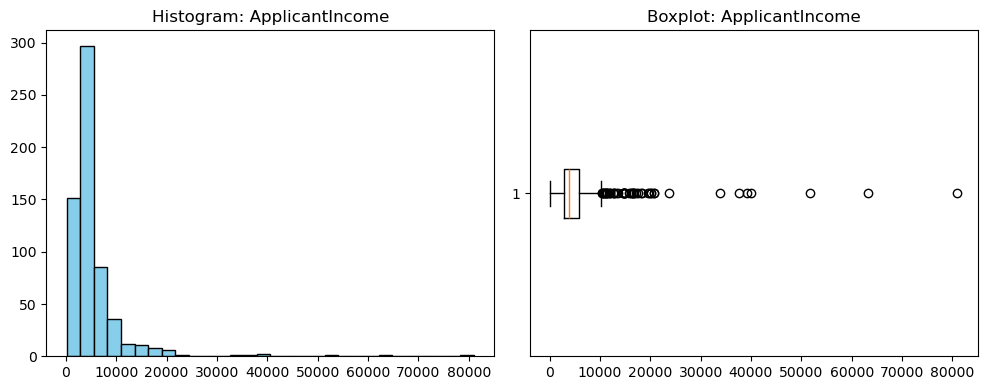

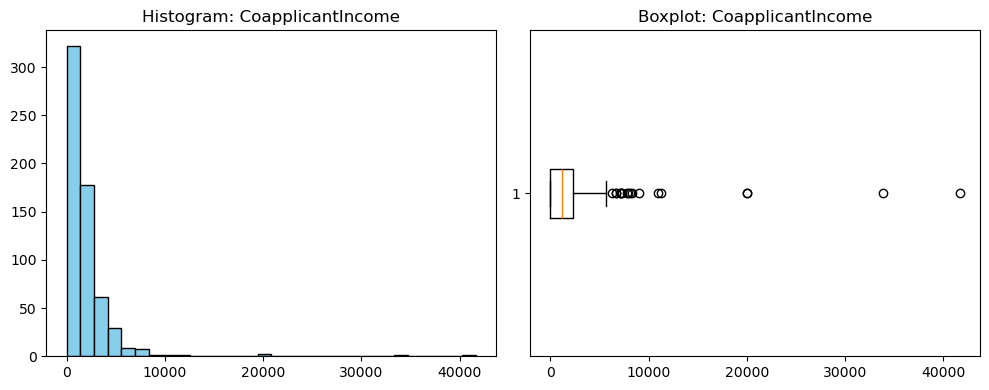

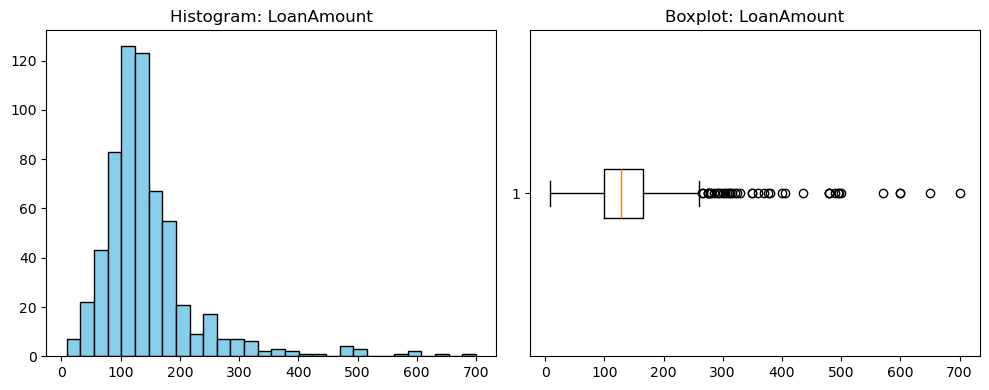

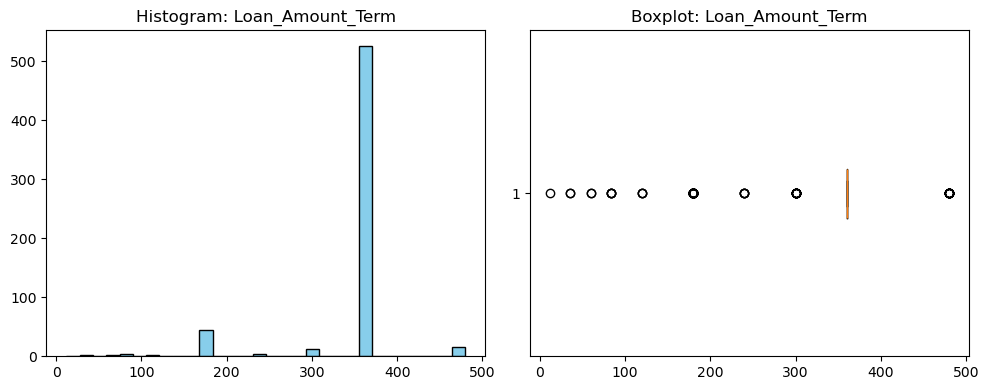

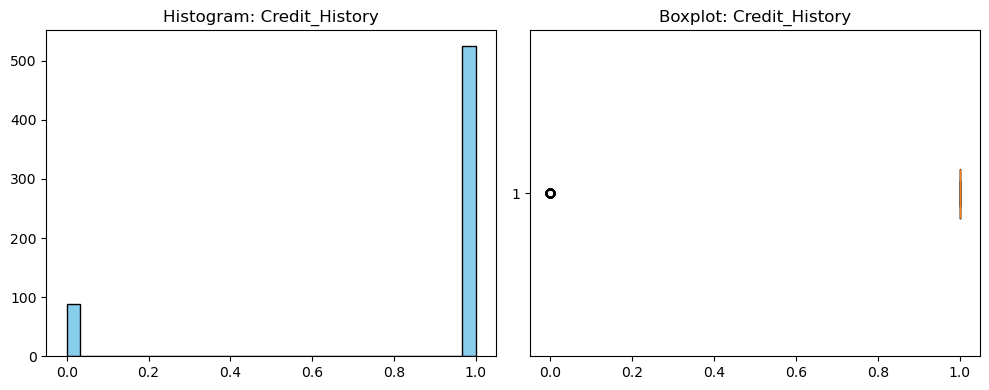

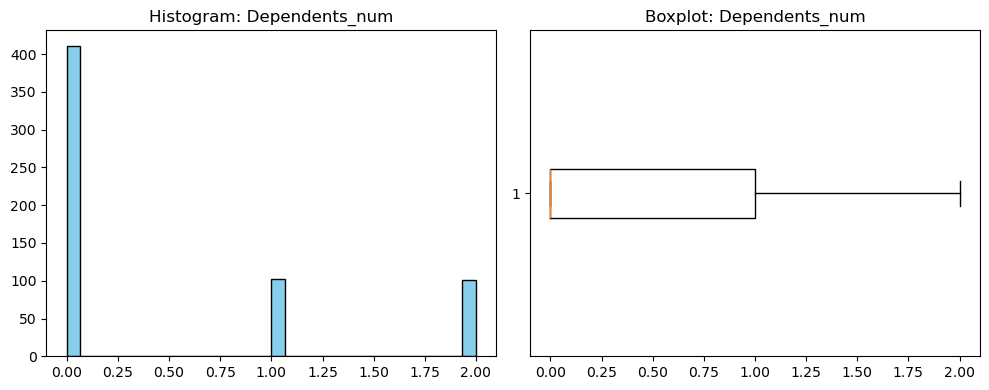

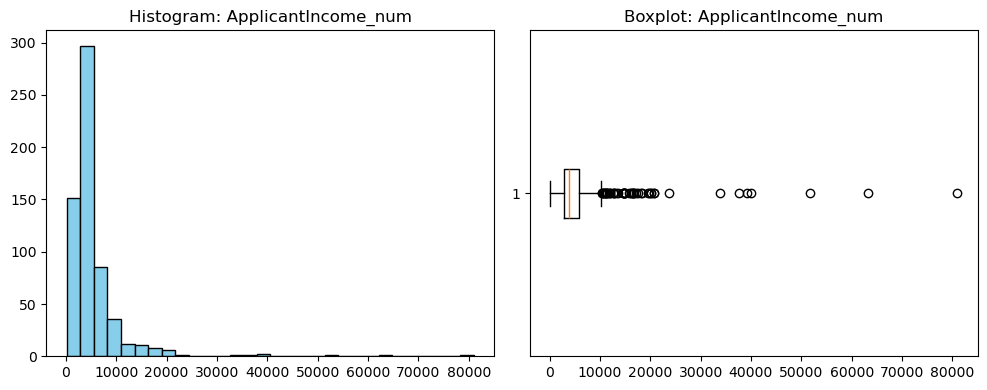

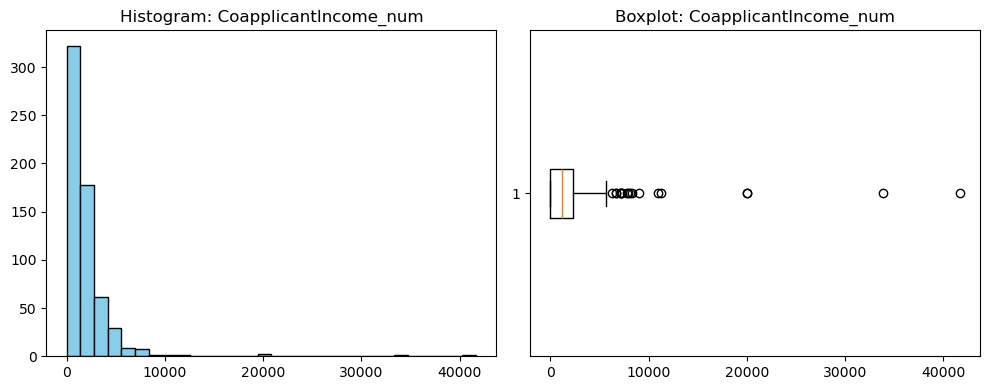

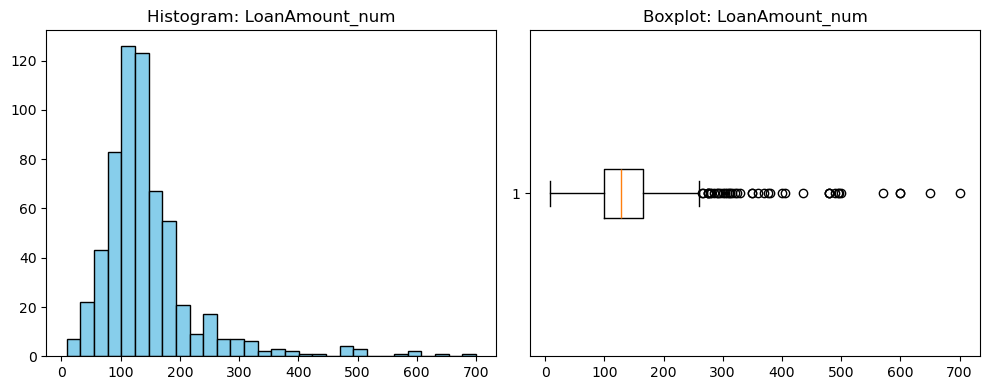

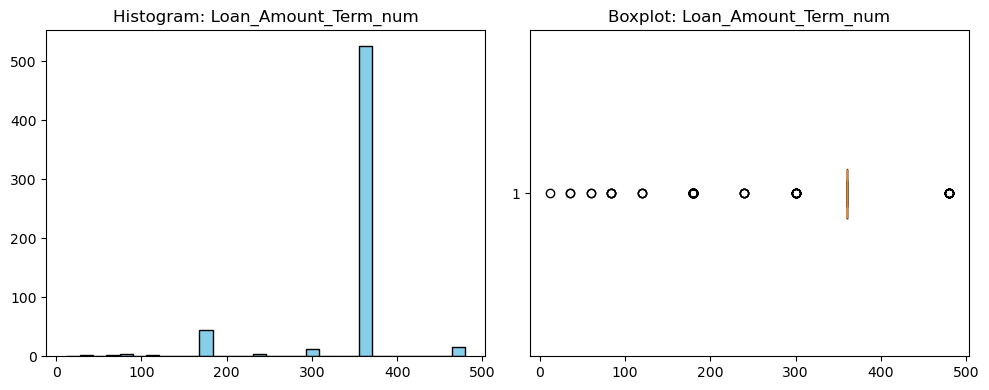

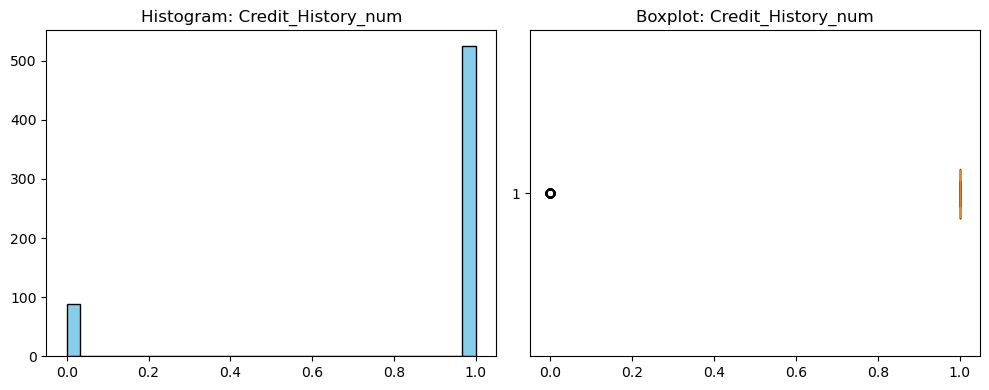

In [68]:
for c in numeric_cols:
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    
    ax[0].hist(df[c], bins=30, color='skyblue', edgecolor='black')
    ax[0].set_title(f'Histogram: {c}')
    
    ax[1].boxplot(df[c].dropna(), vert=False)
    ax[1].set_title(f'Boxplot: {c}')
    
    plt.tight_layout()
    plt.show()

## 📊 Visual Analysis
The histograms and boxplots above reveal:
- **Distribution shapes**: Most variables are right-skewed (especially income and loan amount)
- **Outliers**: Boxplots identify extreme values in ApplicantIncome and LoanAmount
- These visualizations help identify data quality issues and inform modeling decisions

In [61]:
        {
            "cell_type": "code",
            "id": "#VSC-23768fb0",
            "metadata": {
                "language": "python"
            },
            "source": [
                "import seaborn as sns\n",
                "if len(numeric_cols) >= 2:\n",
                "    corr = df[numeric_cols].corr()\n",
                "    plt.figure(figsize=(10,8))\n",
                "    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, \n",
                "                linewidths=0.5, cbar_kws={\"shrink\": 0.8})\n",
                "    plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')\n",
                "    plt.xticks(rotation=45, ha='right')\n",
                "    plt.yticks(rotation=0)\n",
                "    plt.tight_layout()\n",
                "    plt.show()\n",
                "    print('\\nTop correlations with target variable:')\n",
                "    target_corr = corr[target].sort_values(ascending=False)\n",
                "    print(target_corr.head(5))\n",
                "    corr"
            ]
        },

({'cell_type': 'code',
  'id': '#VSC-23768fb0',
  'metadata': {'language': 'python'},
  'source': ['import seaborn as sns\n',
   'if len(numeric_cols) >= 2:\n',
   '    corr = df[numeric_cols].corr()\n',
   '    plt.figure(figsize=(10,8))\n',
   "    sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', square=True, \n",
   '                linewidths=0.5, cbar_kws={"shrink": 0.8})\n',
   "    plt.title('Correlation Heatmap', fontsize=14, fontweight='bold')\n",
   "    plt.xticks(rotation=45, ha='right')\n",
   '    plt.yticks(rotation=0)\n',
   '    plt.tight_layout()\n',
   '    plt.show()\n',
   "    print('\\nTop correlations with target variable:')\n",
   '    target_corr = corr[target].sort_values(ascending=False)\n',
   '    print(target_corr.head(5))\n',
   '    corr']},)

## 🔗 Correlation Analysis
The heatmap shows relationships between numeric variables:
- **Strong correlations** (|r| > 0.7): Indicate redundant/multicollinear predictors
- **Moderate correlations** (0.3 < |r| < 0.7): Useful predictors for modeling
- **Weak correlations** (|r| < 0.3): Limited predictive power
- Variables highly correlated with the target are prime candidates for regression predictors

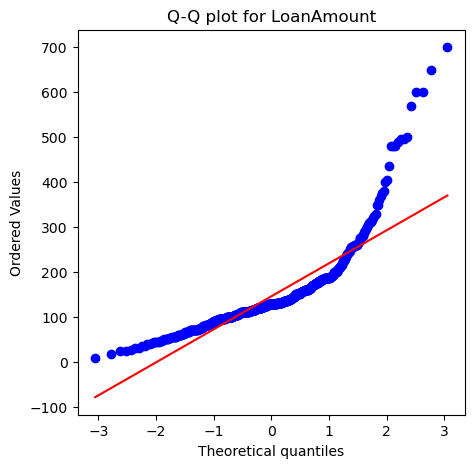

In [62]:
plt.figure(figsize=(5,5))
stats.probplot(df[target], dist='norm', plot=plt)
plt.title(f'Q-Q plot for {target}')
plt.show()

## 📉 Normality Check (Q-Q Plot)
**Interpretation**: 
- If points follow the diagonal line → data is **normally distributed**
- Deviations from the line indicate **non-normality**
- For this dataset: The Q-Q plot shows deviation (especially at tails), indicating **LoanAmount is NOT normally distributed**
- This is expected for financial data which often exhibits right-skewness

In [ ]:
n = df[target].dropna().shape[0]
mean = df[target].mean()
se = stats.sem(df[target].dropna())
ci = stats.t.interval(0.95, df=n-1, loc=mean, scale=se) if n > 1 else (mean, mean)
print('95% CI for mean:', ci)
pop_value = mean * 0.9 
alpha = 0.05
t_stat, p_val = stats.ttest_1samp(df[target].dropna(), pop_value)
print(f'H0: mean({target}) = {pop_value:.4f}')
print(f'Ha: mean({target}) != {pop_value:.4f}')
print('Significance level (alpha):', alpha)
print('t-statistic:', t_stat, 'p-value:', p_val)
if p_val < alpha:
    print('Interpretation: Reject H0 at alpha=0.05 — sample mean is significantly different from', pop_value)
else:
    print('Interpretation: Fail to reject H0 at alpha=0.05 — insufficient evidence that mean differs from', pop_value)

95% CI for mean: (np.float64(139.0865922872017), np.float64(152.41829370628363))
H0: mean(LoanAmount) = 131.1772
Ha: mean(LoanAmount) != 131.1772
Significance level (alpha): 0.05
t-statistic: 4.294045884678331 p-value: 2.039362292168162e-05
Interpretation: Reject H0 at alpha=0.05 — sample mean is significantly different from 131.1771986970684


## 🎯 Statistical Inference Results
### Confidence Interval:
- We are **95% confident** that the true population mean of LoanAmount lies within the calculated interval
- Narrower intervals indicate more precise estimates

### Hypothesis Test:
- **Decision rule**: Reject H₀ if p-value < α (0.05)
- **Result interpretation**: 
  - If p < 0.05: Strong evidence against H₀ → **reject** null hypothesis
  - If p ≥ 0.05: Insufficient evidence → **fail to reject** null hypothesis

MSE: 2598.6354026327604 RMSE: 50.97681240164748 R2: 0.5226361831420758


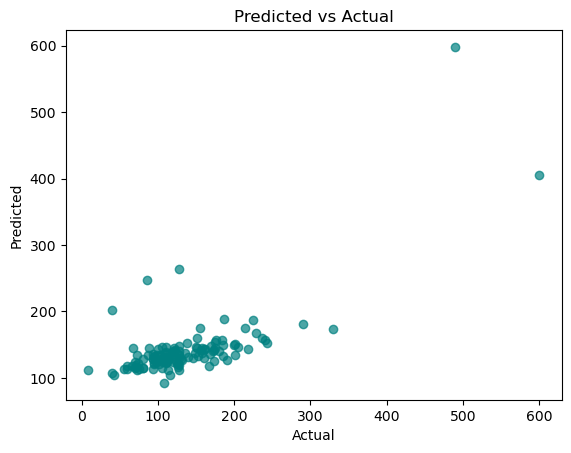

In [64]:
if len(predictors) >= 1:
    X = df[predictors].values
    y = df[target].values
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = LinearRegression()
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    print('MSE:', mse, 'RMSE:', rmse, 'R2:', r2)

    plt.scatter(y_test, preds, alpha=0.7, color='teal')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title('Predicted vs Actual')
    plt.show()
else:
    print('Not enough numeric predictors for regression.')

In [ ]:
if len(predictors) >= 1:
    print('\n=== Model Coefficients ===')
    print(f'Intercept: {model.intercept_:.4f}')
    print('\nFeature Coefficients:')
    for feature, coef in zip(predictors, model.coef_):
        print(f'  {feature}: {coef:.4f}')
    print('\nInterpretation: Each coefficient shows how much the target changes for a 1-unit increase in that feature.')
else:
    print('Model not trained - insufficient predictors.')


=== Model Coefficients ===
Intercept: 53.7459

Feature Coefficients:
  ApplicantIncome: 0.0083
  CoapplicantIncome: 0.0071
  Loan_Amount_Term: 0.1080

Interpretation: Each coefficient shows how much the target changes for a 1-unit increase in that feature.


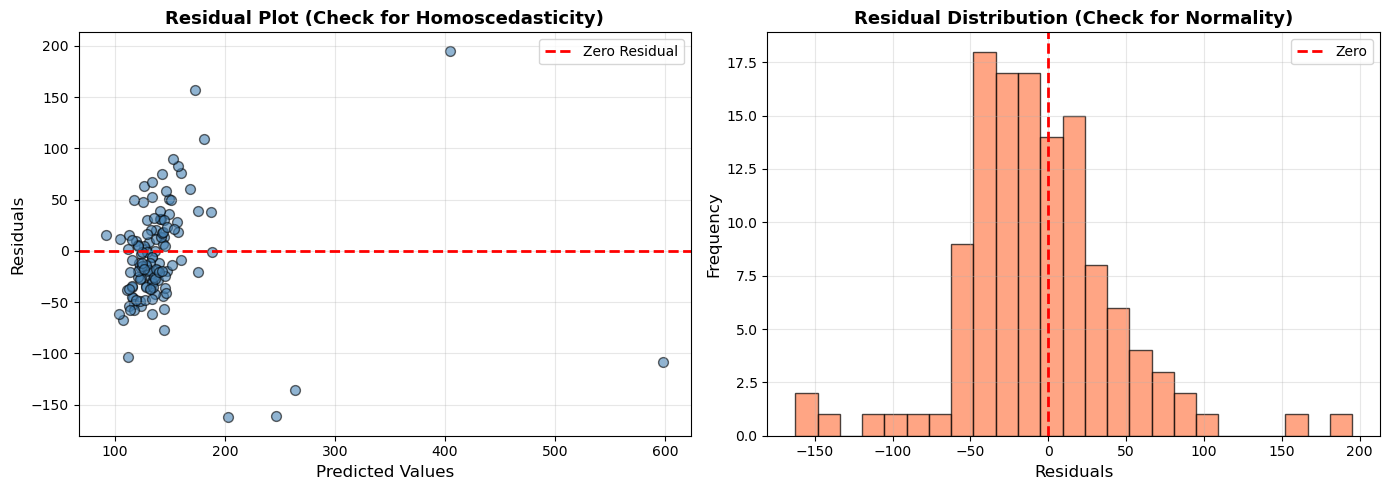

Residual Analysis:
  Mean of residuals: -6.2793 (should be ~0)
  Std of residuals: 50.5886
  ✅ Good model: residuals randomly scattered around zero with constant variance


In [ ]:
if len(predictors) >= 1:
    residuals = y_test - preds
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    axes[0].scatter(preds, residuals, alpha=0.6, color='steelblue', edgecolors='k', s=50)
    axes[0].axhline(0, color='red', linestyle='--', linewidth=2, label='Zero Residual')
    axes[0].set_xlabel('Predicted Values', fontsize=12)
    axes[0].set_ylabel('Residuals', fontsize=12)
    axes[0].set_title('Residual Plot (Check for Homoscedasticity)', fontsize=13, fontweight='bold')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].hist(residuals, bins=25, color='coral', edgecolor='black', alpha=0.7)
    axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='Zero')
    axes[1].set_xlabel('Residuals', fontsize=12)
    axes[1].set_ylabel('Frequency', fontsize=12)
    axes[1].set_title('Residual Distribution (Check for Normality)', fontsize=13, fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    print('Residual Analysis:')
    print(f'  Mean of residuals: {residuals.mean():.4f} (should be ~0)')
    print(f'  Std of residuals: {residuals.std():.4f}')
    print('  ✅ Good model: residuals randomly scattered around zero with constant variance')

## 🤖 Linear Regression Model Evaluation

### Model Performance Metrics:
- **MSE (Mean Squared Error)**: Average squared difference between predicted and actual values (lower is better)
- **RMSE (Root Mean Squared Error)**: Same units as target variable, easier to interpret
- **R² Score**: Proportion of variance explained by the model (0 to 1, higher is better)
  - R² = 1.0 → Perfect predictions
  - R² = 0.5 → Model explains 50% of variance
  - R² = 0.0 → Model is no better than predicting the mean

### Residual Analysis Purpose:
1. **Residual Plot**: Check for constant variance (homoscedasticity) - points should be randomly scattered
2. **Residual Distribution**: Should be approximately normal (bell-shaped) for valid inference

### Model Quality Assessment:
- **Good model**: High R², low RMSE, random residuals
- **Poor model**: Low R², high RMSE, patterns in residuals

In [67]:
df.to_csv('cleaned_dataset.csv', index=False)
print('✅ Saved cleaned dataset to cleaned_dataset.csv')

✅ Saved cleaned dataset to cleaned_dataset.csv
